# Chiến lược H1: Touch + Hướng (model B: giá + vị thế)

**Cấu hình đồng thuận (2026-10-13):** touch dự báo biến động b, TP cũng là b.
- **Touch H1:** chạm ±b trong 8 nến 1h, b = clip(σ_1h·√8, 1%, 5%); tín hiệu khi p_touch ≥ ngưỡng top 20%.
- **Model hướng B:** train trên các lần thực sự chạm; 101 feature touch + 20 feature có hướng + 18 feature vị thế; chỉ vào lệnh khi độ tự tin thuộc top 10%.
- **Lệnh:** vào ở open nến 1h kế tiếp, TP = 1b, SL = 0.75b, giữ tới khi chạm; tối đa 5 lệnh cùng lúc; phí 0.1%; rủi ro mặc định 1% vốn / lệnh.
- **Thoát nhanh (nến 5m):** một nến 5m ngược chiều lệnh có range ≥ 0.75% → đóng lệnh ở close nến đó. Backtest chạy trên nến 5m (backtest nến 1h giữ làm tham chiếu).
- **Walk-forward 2023–2026:** train < Y−1, dừng sớm + calibration trên Y−1, test Y.

Chạy từ thư mục gốc `BTC_PIPELINE`. Cần các file `historical_data/BTCUSDT_5m_all.csv`, `BTCUSDT_funding.csv`, `BTCUSDT_positioning_5m.csv`.

In [1]:
import sys, warnings
sys.path.insert(0, 'model_training'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
import strategy_h1 as st
pd.set_option('display.width', 220)
cfg = st.StrategyConfig()          # risk_per_trade = 1%
cfg

StrategyConfig(csv_5m='historical_data/BTCUSDT_5m_all.csv', csv_1h='historical_data/BTCUSDT_1h_from5m.csv', positioning_csv='historical_data/BTCUSDT_positioning_5m.csv', output_dir='artifacts/1h_strategy_v1', horizon=8, pivot_reversal=0.01, lookback_bars=168, vol_span=168, slow_vol_span=720, b_mult=1.0, min_barrier=0.01, max_barrier=0.05, touch_top=0.2, dir_top=0.1, tp_mult=1.0, sl_mult=0.75, max_hold_bars=720, max_positions=5, min_gap_bars=1, fee_pct=0.001, risk_per_trade=0.01, anomaly_range=0.0075, entry_mode='next_open', entry_delay_m5=0, confirm_window_m5=6, eval_years=(2023, 2024, 2025, 2026), val_es_frac=0.6, seed=42, xgb_device='cpu', n_boot=200)

In [2]:
# 1) Gộp nến 5m -> 1h
st.make_1h_csv(cfg.csv_5m, cfg.csv_1h).tail(3)

,timestamp,open,high,low,close,volume,taker_buy_volume,trades
54976,2026-10-08 16:00:00+00:00,80990.7,81418.5,80716.0,80915.9,20384.165,9704.464,446452.0
54977,2026-10-08 17:00:00+00:00,80916.0,80989.0,80344.8,80718.1,18359.053,8164.189,350706.0
54978,2026-10-08 18:00:00+00:00,80718.1,81537.0,80505.0,81466.9,12514.392,7274.786,228763.0


In [3]:
# 2) Train walk-forward + tín hiệu + backtest 5m có thoát nhanh (vài phút)
res = st.walk_forward(cfg)
print('Tham chiếu nến 1h:', {k: round(v, 3) for k, v in res['summary_1h'].items() if isinstance(v, float)})

2023: touch AUC 0.636 | AUC hướng 0.597 | 359 giờ có tín hiệu | đúng hướng 0.654
2024: touch AUC 0.737 | AUC hướng 0.595 | 198 giờ có tín hiệu | đúng hướng 0.623
2025: touch AUC 0.722 | AUC hướng 0.552 | 130 giờ có tín hiệu | đúng hướng 0.709
2026: touch AUC 0.735 | AUC hướng 0.599 | 168 giờ có tín hiệu | đúng hướng 0.689
Backtest nến 1h (tham chiếu, không thoát nhanh): 769 lệnh | R/lệnh +0.132 | vốn x2.42 | sụt giảm 28.8%
Backtest 5m (thực thi chính): 772 lệnh | R/lệnh +0.157 | vốn x2.98 | sụt giảm 19.7% | R theo năm {2023: 28.348324771212503, 2024: 34.54406218839521, 2025: 31.127512101097093, 2026: 27.164490335199392}
Tham chiếu nến 1h: {'win_rate': 0.532, 'R_per_trade': 0.132, 'total_R': 101.683, 'max_dd_R': 30.869, 'max_dd_pct': 28.829, 'equity_multiple': 2.424}


In [4]:
# 3) Chất lượng model theo năm
pd.DataFrame(res['folds']).round(3)

,year,touch_auc,dir_auc_touched,signal_hours,dir_hit_on_touched_signals,thr_touch,thr_conf,dir_rounds
0,2023,0.636,0.597,359,0.654,0.595,0.094,105
1,2024,0.737,0.595,198,0.623,0.603,0.203,421
2,2025,0.722,0.552,130,0.709,0.717,0.153,233
3,2026,0.735,0.599,168,0.689,0.648,0.103,69


In [5]:
# 4) Tổng quan backtest
s = res['summary']
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in s.items() if not isinstance(v, dict)})
pd.DataFrame({'R': s['R_by_year'], 'lệnh': s['trades_by_year']}).round(1)

{'trades': 772, 'win_rate': 0.531, 'R_per_trade': 0.157, 'total_R': 121.184, 'max_dd_R': 20.856, 'max_dd_pct': 19.691, 'equity_multiple': 2.979, 'negative_quarters': 4}


,R,lệnh
2023,28.3,311
2024,34.5,188
2025,31.1,127
2026,27.2,146


In [6]:
# 5) R theo quý
pd.Series(s['R_by_quarter']).round(1).to_frame('R')

,R
2023Q1,10.7
2023Q2,19.4
2023Q3,-4.9
2023Q4,3.1
2024Q1,-3.1
2024Q2,1.8
2024Q3,21.8
2024Q4,14.0
2025Q1,9.0
2025Q2,28.0


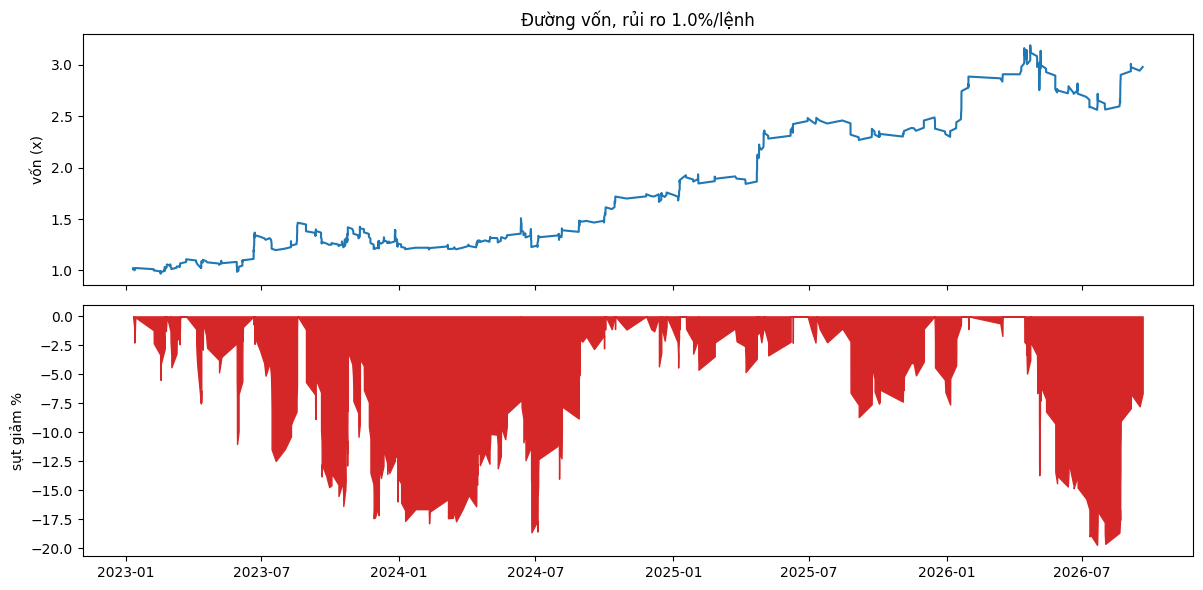

In [7]:
# 6) Đường vốn và sụt giảm
eq = res['equity']
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(eq.time, eq.equity); ax[0].set_ylabel('vốn (x)'); ax[0].set_title(f'Đường vốn, rủi ro {cfg.risk_per_trade:.1%}/lệnh')
dd = 1 - eq.equity / eq.equity.cummax(); ax[1].fill_between(eq.time, -dd * 100, color='tab:red'); ax[1].set_ylabel('sụt giảm %')
plt.tight_layout(); plt.show()

In [8]:
# 7) Độ nhạy theo mức rủi ro mỗi lệnh (thực thi 5m + thoát nhanh)
rows = []
for r in (0.015, 0.01, 0.0075, 0.005):
    T, curve = st.backtest_m5(res['data'], res['signals'], replace(cfg, risk_per_trade=r), res['candles_5m'])
    x = st.summarize(T, curve)
    rows.append({'rủi ro/lệnh': f'{r:.2%}', 'vốn x': x['equity_multiple'], 'sụt giảm %': x['max_dd_pct'], 'R/lệnh': x['R_per_trade'], 'lệnh': x['trades']})
res['risk_sensitivity'] = rows
pd.DataFrame(rows).round(3)

,rủi ro/lệnh,vốn x,sụt giảm %,R/lệnh,lệnh
0,1.50%,4.705,28.614,0.157,772
1,1.00%,2.979,19.691,0.157,772
2,0.75%,2.319,14.994,0.157,772
3,0.50%,1.778,10.143,0.157,772


In [9]:
# 7b) Thời điểm vào lệnh: vào ngay / chờ k nến 5m / chờ nến 5m xác nhận cùng chiều (đều có thoát nhanh)
variants = [('vào ngay (open nến 1h kế tiếp)', dict()), ('không thoát nhanh', dict(anomaly_range=0.0))]
variants += [(f'chờ {k} nến 5m', dict(entry_mode='delay', entry_delay_m5=k)) for k in (1, 2, 3, 6, 9)]
variants += [(f'xác nhận nến 5m cùng chiều (≤{w*5} phút)', dict(entry_mode='confirm', confirm_window_m5=w)) for w in (3, 6)]
rows = []
for nm, kw in variants:
    T, curve = st.backtest_m5(res['data'], res['signals'], replace(cfg, **kw), res['candles_5m'])
    x = st.summarize(T, curve)
    rows.append({'thực thi': nm, 'lệnh': x['trades'], 'win': x['win_rate'], 'R/lệnh': x['R_per_trade'], 'vốn x': x['equity_multiple'],
                 'sụt giảm %': x['max_dd_pct'], 'quý âm': x['negative_quarters'], **{f'R {k}': v for k, v in x['R_by_year'].items()},
                 'thoát nhanh': int((T.result == 'thoát nhanh 5m').sum())})
res['entry_timing'] = rows
pd.DataFrame(rows).round(3)

,thực thi,lệnh,win,R/lệnh,vốn x,sụt giảm %,quý âm,R 2023,R 2024,R 2025,R 2026,thoát nhanh
0,vào ngay (open nến 1h kế tiếp),772,0.531,0.157,2.979,19.691,4,28.348,34.544,31.128,27.164,93
1,không thoát nhanh,769,0.536,0.141,2.597,27.201,6,35.407,20.272,33.930,19.074,0
2,chờ 1 nến 5m,769,0.528,0.131,2.438,20.133,3,18.719,29.527,26.145,26.599,88
3,chờ 2 nến 5m,767,0.523,0.130,2.412,19.088,4,23.433,19.647,23.901,33.008,90
4,chờ 3 nến 5m,763,0.523,0.123,2.249,20.374,4,24.876,21.701,22.987,24.051,89
5,chờ 6 nến 5m,762,0.529,0.137,2.526,19.953,3,34.118,22.217,25.643,22.763,96
6,chờ 9 nến 5m,759,0.545,0.182,3.532,22.377,3,44.083,24.968,32.746,36.581,93
7,xác nhận nến 5m cùng chiều (≤15 phút),701,0.509,0.096,1.754,22.502,6,3.456,13.089,25.250,25.195,83
8,xác nhận nến 5m cùng chiều (≤30 phút),762,0.517,0.111,2.075,20.646,5,12.238,19.874,30.790,21.902,91


In [10]:
# 8) Danh sách lệnh
res['trades'].tail(10)

,signal_time,entry_time,exit_time,side,entry,tp,sl,exit,b_pct,sl_pct,p_touch,p_up,result,R_gross,R
762,2026-08-20 17:00:00+00:00,2026-08-20 18:00:00+00:00,2026-08-21 00:15:00+00:00,long,72694.5,73821.384309,71860.639946,73821.384309,1.538272,1.153704,0.768485,0.617111,TP,1.333333,1.246656
763,2026-08-20 18:00:00+00:00,2026-08-20 19:00:00+00:00,2026-08-21 00:15:00+00:00,long,72398.4,73517.770082,71570.071399,73517.770082,1.534295,1.150721,0.741857,0.610162,TP,1.333333,1.246431
764,2026-08-21 06:00:00+00:00,2026-08-21 07:00:00+00:00,2026-08-21 07:15:00+00:00,long,75613.3,76850.257209,74698.665427,76850.257209,1.622662,1.216997,0.692076,0.634646,TP,1.333333,1.251164
765,2026-08-21 07:00:00+00:00,2026-08-21 08:00:00+00:00,2026-08-21 08:35:00+00:00,long,76310.3,77570.215476,75378.811079,77570.215476,1.637561,1.228171,0.765507,0.630662,TP,1.333333,1.251911
766,2026-09-03 15:00:00+00:00,2026-09-03 16:00:00+00:00,2026-09-04 06:35:00+00:00,long,81316.7,82322.935606,80570.102929,80570.102929,1.229834,0.922376,0.678558,0.607166,SL,-1.000000,-1.108416
767,2026-09-03 16:00:00+00:00,2026-09-03 17:00:00+00:00,2026-09-03 21:30:00+00:00,long,80937.3,81939.775403,80193.500316,81939.775403,1.230975,0.923231,0.681262,0.609764,TP,1.333333,1.225018
768,2026-09-03 17:00:00+00:00,2026-09-03 18:00:00+00:00,2026-09-03 21:30:00+00:00,long,81006.8,82004.379496,80266.587410,82004.379496,1.223955,0.917966,0.678170,0.614655,TP,1.333333,1.224397
769,2026-09-03 18:00:00+00:00,2026-09-03 19:00:00+00:00,2026-09-03 21:30:00+00:00,long,81226.7,82223.358769,80487.142025,82223.358769,1.219542,0.914657,0.701776,0.630219,TP,1.333333,1.224003
770,2026-09-15 14:00:00+00:00,2026-09-15 15:00:00+00:00,2026-09-15 15:25:00+00:00,short,75906.9,75151.613725,76478.341979,76478.341979,1.000000,0.750000,0.658872,0.395366,SL,-1.000000,-1.133333
771,2026-09-18 14:00:00+00:00,2026-09-18 15:00:00+00:00,2026-09-19 15:40:00+00:00,long,80905.9,81904.039490,80165.286159,81904.039490,1.226156,0.919617,0.765892,0.604894,TP,1.333333,1.224592


In [11]:
# 9) Lưu model cuối (fold năm cuối) + kết quả vào artifacts/1h_strategy_v1
st.export_bundle(cfg, res)

WindowsPath('artifacts/1h_strategy_v1')

In [12]:
# 10) Tín hiệu live cho các nến 1h đã đóng gần nhất
bundle = st.load_bundle(f'{cfg.output_dir}/models_final.joblib')
candles = pd.read_csv(cfg.csv_1h).tail(24 * 90)
pos = pd.read_csv(cfg.positioning_csv)
fund = pd.read_csv('historical_data/BTCUSDT_funding.csv')
st.predict_live(bundle, candles, pos, fund, last_n=5)

# Khi đang giữ lệnh: kiểm tra mỗi nến 5m vừa đóng
# st.anomaly_exit(side=+1, candle_5m={'open': o, 'high': h, 'low': l, 'close': c}, cfg=cfg)  -> True thì đóng lệnh

,bar,timestamp,close,b,p_touch,p_up,conf,signal,side,tp_price,sl_price
0,2155,2026-10-08 14:00:00+00:00,82660.5,0.010000,0.582901,0.432626,0.067374,False,-1,81838.014283,83282.784400
1,2156,2026-10-08 15:00:00+00:00,80990.7,0.010998,0.773631,0.415659,0.084341,False,-1,80104.808736,81661.541960
2,2157,2026-10-08 16:00:00+00:00,80915.9,0.010937,0.789694,0.395224,0.104776,True,-1,80035.755152,81582.354588
3,2158,2026-10-08 17:00:00+00:00,80718.1,0.010898,0.821166,0.391631,0.108369,True,-1,79843.209077,81380.553749
4,2159,2026-10-08 18:00:00+00:00,81466.9,0.011200,0.625496,0.394649,0.105351,False,-1,80559.584008,82154.086810
